# Case Study 1 

## 0. Configuration

In [31]:
from pathlib import Path
import re, json, hashlib
import numpy as np
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt
from IPython.display import display

# Every new result is saved here.
OUT = Path("../Results/Component_analysis_outputs")
OUT.mkdir(parents=True, exist_ok=True)

# Inputs: these are read only and are never overwritten.
LOG_PATH = Path("../Results/Component_selection_outputs/clingo_optimization.log")
CANDIDATE_SIF = Path("../Results/Component_selection_outputs/hematopoiesis_seed_network.sif")
FULL_SIF = Path("../Data/dorothea_ABC_20210707_TF.sif")
NCBI_INFO = Path("../Data/Mus_musculus.gene_info.202103.tsv")
OBS_CSV = Path("../Data/nestorowa_singlecell_binarized_observations.csv")
MSIGDB_GMT = Path("../Data/msigdb.v2026.1.Mm.symbols.gmt")

for path in (LOG_PATH, CANDIDATE_SIF, FULL_SIF):
    if not path.is_file():
        raise FileNotFoundError(f"Required input file is missing: {path}")

print("Clingo log:", LOG_PATH.resolve())
print("All generated outputs:", OUT.resolve())


Clingo log: /home/eren/CSBC_CLEAN/Results/Component_selection_outputs/clingo_optimization.log
All generated outputs: /home/eren/CSBC_CLEAN/Results/Component_analysis_outputs


## 1. Read the proven-optimal Clingo solution

Clingo may print many **intermediate answers** before finding the best one.
We require `OPTIMUM FOUND` in the log and use **only the final answer**, which has the proven-optimal objective. There is no `selection_mode`: this notebook does not rank or manually select answers.


In [32]:
log_text = LOG_PATH.read_text(encoding='utf-8', errors='replace')
# Match each answer body to its *own* following optimization line, not the footer.
pattern = re.compile(
    r'(?ms)^Answer:\s*(\d+)([^\n]*)\n(.*?)^Optimization:\s*(-?\d+)\s+(-?\d+)\s*$'
)
clingo_answers = []
for match in pattern.finditer(log_text):
    answer_id = int(match.group(1))
    header = match.group(2)
    atoms = match.group(3)
    selected = set(re.findall(r'\bnode\("([^"\n]+)"\)', atoms))
    constants = set(re.findall(r'\bstrong_constant\("([^"\n]+)"\)', atoms))
    nodes_score, constants_score = -int(match.group(4)), -int(match.group(5))
    if not selected or not constants <= selected:
        raise ValueError(f'Answer {answer_id}: invalid selected nodes / strong constants')
    if len(selected) != nodes_score or len(constants) != constants_score:
        raise ValueError(
            f'Answer {answer_id}: optimization score ({nodes_score}, {constants_score}) '
            f'disagrees with atom counts ({len(selected)}, {len(constants)}).'
        )
    t = re.search(r'Time:\s*([\d.]+)s', header)
    clingo_answers.append({
        'answer_id': answer_id,
        'time_s': float(t.group(1)) if t else float('nan'),
        'selected': selected,
        'constants': constants,
        'nonconstant': selected - constants,
        'n_selected': nodes_score,
        'n_constants': constants_score,
    })

if not clingo_answers:
    raise RuntimeError('No complete Clingo Answer + Optimization pairs in the supplied log.')
raw_answer_headers = len(re.findall(r'(?m)^Answer:\s*\d+', log_text))
if len(clingo_answers) != raw_answer_headers:
    raise RuntimeError(
        f'Found {raw_answer_headers} Answer headers but could parse only {len(clingo_answers)} '
        'complete Answer + Optimization pairs. Please inspect the log formatting.'
    )
if len({a['answer_id'] for a in clingo_answers}) != len(clingo_answers):
    raise ValueError('Duplicate Answer IDs. Is the log a concatenation of multiple solver runs?')

# Require a certified global optimum; no fallback to time-limited feasible answers.
all_parsed_answers = clingo_answers
n_parsed_answers = len(all_parsed_answers)
proven_optimum = bool(re.search(
    r'(?im)^\s*OPTIMUM FOUND\s*$|^\s*Optimum\s*:\s*yes\s*$', log_text
))
if not proven_optimum:
    raise RuntimeError(
        'This notebook analyzes ONLY proven Clingo optima. '
        'The log must report OPTIMUM FOUND (or Optimum: yes). '
        'Complete the Clingo optimization and set LOG_PATH to its finished log.'
    )

# In a completed single-run Clingo log, the last answer has the proven
# lexicographically optimal objective: maximize nodes, then strong constants.
best_objective = (
    all_parsed_answers[-1]['n_selected'],
    all_parsed_answers[-1]['n_constants'],
)
if any((a['n_selected'], a['n_constants']) > best_objective for a in all_parsed_answers):
    raise RuntimeError(
        'The log claims OPTIMUM FOUND but an earlier answer has a better '
        'objective than the final one. Check for concatenated or mixed logs.'
    )

# Only the final answer is used for every downstream calculation.
# Earlier answers are intermediate solutions, even if they have the same objective.
chosen = all_parsed_answers[-1]
clingo_answers = [chosen]
selected_answer_id = chosen['answer_id']
comparison_scope = 'final_proven_optimum_only'

# Save objective values for auditing; this does not analyze intermediate answers.
objective_audit = pd.DataFrame([
    {
        'answer_id': a['answer_id'],
        'n_selected': a['n_selected'],
        'n_strong_constants': a['n_constants'],
        'is_final_proven_optimum': a['answer_id'] == selected_answer_id,
    }
    for a in all_parsed_answers
])
objective_audit.to_csv(OUT / 'clingo_answer_objective_audit.csv', index=False)

print('Clingo answers in log:', n_parsed_answers)
print('Final proven-optimal answer:', selected_answer_id)
print('Optimal objective (selected genes, strong constants):', best_objective)
print('All downstream analyses use only this final answer.')


Clingo answers in log: 195
Final proven-optimal answer: 195
Optimal objective (selected genes, strong constants): (129, 29)
All downstream analyses use only this final answer.


## 2. Load the regulatory networks and binarized observations

Read the two SIF networks and the six-state observation table. Each SIF row contains **source gene, interaction sign, target gene**. The selected regulatory core will be the largest strongly connected component (SCC) after removing strong constants.

In [33]:
# Read a three-column SIF without changing source/sign/target order.
def load_sif(path):
    edges = pd.read_csv(path, sep=r"\s+", header=None, comment="#", dtype=str)
    if edges.shape[1] != 3:
        raise ValueError(f"Expected three SIF columns (source, sign, target) in {path}")
    edges.columns = ['source', 'sign', 'target']
    return edges.drop_duplicates().reset_index(drop=True)

candidate_edges = load_sif(CANDIDATE_SIF)
full_edges = load_sif(FULL_SIF)

# A directed graph defines connectivity; the DataFrame retains signed edges.
G_candidate = nx.DiGraph()
G_candidate.add_edges_from(zip(candidate_edges.source, candidate_edges.target))
candidate_nodes = set(G_candidate.nodes())

# Keep S0-S5 as rows and genes as columns.
if not OBS_CSV.is_file():
    raise FileNotFoundError(f"Required observation table: {OBS_CSV}")
obs_df = pd.read_csv(OBS_CSV, index_col=0)
obs_df.index = obs_df.index.astype(str)

# Standardize mouse gene symbols to uppercase
obs_df.columns = obs_df.columns.astype(str).str.strip().str.upper()

# Check for duplicate gene names after standardization
if obs_df.columns.duplicated().any():
    raise ValueError("Duplicate gene names after converting to uppercase")

if not {'S0', 'S1', 'S2', 'S3', 'S4', 'S5'}.issubset(obs_df.index):
    if {'S0', 'S1', 'S2', 'S3', 'S4', 'S5'}.issubset(obs_df.columns):
        obs_df = obs_df.T
    else:
        raise ValueError('Observation CSV must contain states S0-S5 as rows or columns.')
obs_df = obs_df.loc[['S0', 'S1', 'S2', 'S3', 'S4', 'S5']]
obs_df = obs_df.replace({'ND': np.nan, 'N/D': np.nan})
obs_df = obs_df.apply(pd.to_numeric, errors='raise')

print('Candidate network:', len(candidate_nodes), 'genes,', len(candidate_edges), 'signed regulations')
print('Full network:', len(set(full_edges.source) | set(full_edges.target)), 'genes,', len(full_edges), 'signed regulations')
print('Observations:', obs_df.shape[0], 'states x', obs_df.shape[1], 'genes')

Candidate network: 149 genes, 633 signed regulations
Full network: 1001 genes, 2776 signed regulations
Observations: 6 states x 4768 genes


## 3. Reference gene sets

These published gene sets are used **only for comparison**, not for selecting the optimal Clingo answer. Similarity is calculated after extracting the SCC.


In [34]:
paper_components = ("ATF3", "ATF7", "CEBPA", "CREM", "E2F1", "EBF1", "ESR1", "FLI1", "FOS", "FOXO3", "FOXP2", "GATA1", "GFI1B", "HBP1", "HNF4A", "IKZF1", "IRF1", "IRF2", "JUN", "JUNB", "KLF1", "KLF6", "MEF2C", "MYB", "MYC", "NFATC1", "NRF1", "RELA", "RUNX1", "SP1", "SPI1", "STAT1", "STAT3", "STAT6", "TBP", "TBX21", "TCF12", "TRP53", "ZEB2")

print("Chevalier 39:",len(paper_components))

hamey = {"BPTF", "PRDM16", "GATA3", "ETV6", "NKX2.3", "HOXA5", "ETS1", "NOTCH", "HOXB4", "GFI1B", "TAL1", "HHEX", "PBX1", "GATA2", "NFE2", "MEIS1", "CBFA2T3H", "ETS2", "GATA1", "LMO2", "LDB1", "IKZF1", "SMARCC1", "FLI1", "LYL1", "HOXA9", "MITF", "RUNX1", "TCF7", "ERG", "MYB"}
collombet = {"CSF1", "CSF1R", "CEBPA", "CEBPB", "MAC1", "RUNX1", "SPI1", "MEF2C", "IKZF1", "GFI1", "EGR1", "E2A", "ID2", "ETS1", "FOXO1", "EBF1", "PAX5", "CD19", "IL7", "IL7R"}
moignard = {"ETV2", "FLI1", "SCL", "GATA1", "NOTCH1", "SOX7", "HOXB4", "LYL1", "IKAROS", "ERG", "PU.1", "MYB", "NFE2", "ETS1", "ETO2", "HHEX", "LMO2", "SOX17", "GFI1", "GFI1B"}

print(f"Hamey: {len(hamey)}")
print(f"Collombet: {len(collombet)}")
print(f"Moignard: {len(moignard)}")

Chevalier 39: 39
Hamey: 31
Collombet: 20
Moignard: 20


In [35]:
import gene_name_standardization as gns
if not NCBI_INFO.is_file():
    raise FileNotFoundError(f'Required NCBI synonym file: {NCBI_INFO}')
synonyms = gns.synonyms_from_NCBI(str(NCBI_INFO))
references = {
    'paper_39': set(paper_components),
    'hamey': gns.set_standardization(hamey, synonyms),
    'collombet': gns.set_standardization(collombet, synonyms),
    'moignard': gns.set_standardization(moignard, synonyms),
}
for label,genes in references.items():
    print(label, len(genes), 'genes; available in the reduced candidate network:', len(genes & candidate_nodes))


paper_39 39 genes; available in the reduced candidate network: 27
hamey 31 genes; available in the reduced candidate network: 15
collombet 20 genes; available in the reduced candidate network: 8
moignard 20 genes; available in the reduced candidate network: 8


## 4. Extract and export the optimal network

Take the **final proven-optimal Clingo answer**, remove its strong constants, and extract the largest SCC. Save the gene lists and SIF networks for downstream BoNesis sampling. No additional answer ranking or manual selection is performed.


In [36]:
# The final Clingo answer was certified in Section 1.
selected_nodes = chosen['selected']
strong_constants = chosen['constants']
nonconstant_nodes = chosen['nonconstant']

# Find the largest strongly connected component (SCC) of nonconstant genes.
nonconstant_graph = G_candidate.subgraph(nonconstant_nodes).copy()
sccs = sorted(
    nx.strongly_connected_components(nonconstant_graph),
    key=lambda genes: (-len(genes), tuple(sorted(genes)))
)
if not sccs:
    raise RuntimeError('No strongly connected components were found.')
core_nodes = set(sccs[0])

# Retain the signed regulations between the selected genes.
nonconstant_edges = candidate_edges.loc[
    candidate_edges.source.isin(nonconstant_nodes)
    & candidate_edges.target.isin(nonconstant_nodes)
].copy()
core_edges = candidate_edges.loc[
    candidate_edges.source.isin(core_nodes)
    & candidate_edges.target.isin(core_nodes)
].copy()

# Export the networks and gene lists to the chosen results folder.
core_path = OUT / 'synthesis_core_network.sif'
nonconstant_path = OUT / 'synthesis_nonconstant_network.sif'
core_edges.to_csv(core_path, sep='\t', header=False, index=False)
nonconstant_edges.to_csv(nonconstant_path, sep='\t', header=False, index=False)

for name, genes in [
    ('selected_genes', selected_nodes),
    ('strong_constants', strong_constants),
    ('nonconstant_genes', nonconstant_nodes),
    ('core_genes', core_nodes),
]:
    (OUT / f'{name}.txt').write_text('\n'.join(sorted(genes)) + '\n')

# Save how this result was obtained, including hashes of the input files.
manifest = {
    'selection': 'final_proven_optimum',
    'clingo_answer_id': int(selected_answer_id),
    'clingo_optimum_proven': proven_optimum,
    'clingo_objective': {
        'n_selected': best_objective[0],
        'n_strong_constants': best_objective[1],
    },
    'log_path': str(LOG_PATH),
    'log_sha256': hashlib.sha256(LOG_PATH.read_bytes()).hexdigest(),
    'candidate_sif_path': str(CANDIDATE_SIF),
    'candidate_sif_sha256': hashlib.sha256(CANDIDATE_SIF.read_bytes()).hexdigest(),
    'n_selected': len(selected_nodes),
    'n_strong_constants': len(strong_constants),
    'n_nonconstant': len(nonconstant_nodes),
    'n_core_genes': len(core_nodes),
    'n_core_signed_edges': len(core_edges),
    'core_sif_sha256': hashlib.sha256(core_path.read_bytes()).hexdigest(),
    'scc_dynamical_compatibility_checked': False,
}
(OUT / 'selection_manifest.json').write_text(json.dumps(manifest, indent=2))

print(f'Optimal answer {selected_answer_id}: {len(selected_nodes)} selected genes, '
      f'{len(strong_constants)} strong constants')
print(f'Largest SCC: {len(core_nodes)} genes and {len(core_edges)} signed edges')
print('Saved the synthesis input files to:', OUT.resolve())
print('Reminder: SCC reduction still requires independent dynamical validation.')


Optimal answer 195: 129 selected genes, 29 strong constants
Largest SCC: 39 genes and 157 signed edges
Saved the synthesis input files to: /home/eren/CSBC_CLEAN/Results/Component_analysis_outputs
Reminder: SCC reduction still requires independent dynamical validation.


## 5. Compare the optimal network with published models

Use the final SCC and broader sets of selected genes to compare against the paper and three published hematopoiesis models.


In [37]:
comparisons={
    'Chevalier (39)':set(paper_components),
    'Our all genes':selected_nodes,
    'Our nonconstant':nonconstant_nodes,
    'Our largest SCC':core_nodes,
    'Hamey 2017':references['hamey'],
    'Collombet 2017':references['collombet'],
    'Moignard 2015':references['moignard'],
}
for name,genes in comparisons.items():
    print(f'{name:26s} {len(genes):4d} genes')


Chevalier (39)               39 genes
Our all genes               129 genes
Our nonconstant             100 genes
Our largest SCC              39 genes
Hamey 2017                   31 genes
Collombet 2017               20 genes
Moignard 2015                20 genes


## 6. Pairwise gene overlap: Jaccard and percentage shared

This section compares every gene set with every other set.

- **Jaccard index:** Number of shared genes divided by the number of unique genes across both sets. It ranges from 0 to 1.
- **% of set A also in set B:** Of all genes in set A, what percentage occur in set B? `100 × shared / size of A`.
- **% of set B also in set A:** Of all genes in set B, what percentage occur in set A? `100 × shared / size of B`.

percent_of_a_in_b: percentage of our SCC genes found in the comparison set
percent_of_b_in_a: percentage of the comparison set genes found in our SCC


,set_b,n_a,n_b,intersection,jaccard,percent_of_a_in_b,percent_of_b_in_a,common_genes
21,Chevalier (39),39,39,21,0.368421,53.846154,53.846154,ATF3; CEBPA; CREM; E2F1; FLI1; FOS; GATA1; GFI...
22,Our all genes,39,129,39,0.302326,100.000000,30.232558,AR; ATF3; CEBPA; CREB1; CREM; E2F1; E2F6; ELF3...
23,Our nonconstant,39,100,39,0.390000,100.000000,39.000000,AR; ATF3; CEBPA; CREB1; CREM; E2F1; E2F6; ELF3...
25,Hamey 2017,39,31,11,0.186441,28.205128,35.483871,ETS1; ETS2; FLI1; GATA1; GATA3; GFI1B; MITF; M...
26,Collombet 2017,39,20,6,0.113208,15.384615,30.000000,CEBPA; ETS1; MEF2C; PAX5; RUNX1; SPI1
27,Moignard 2015,39,20,6,0.113208,15.384615,30.000000,ETS1; FLI1; GATA1; GFI1B; MYB; SPI1


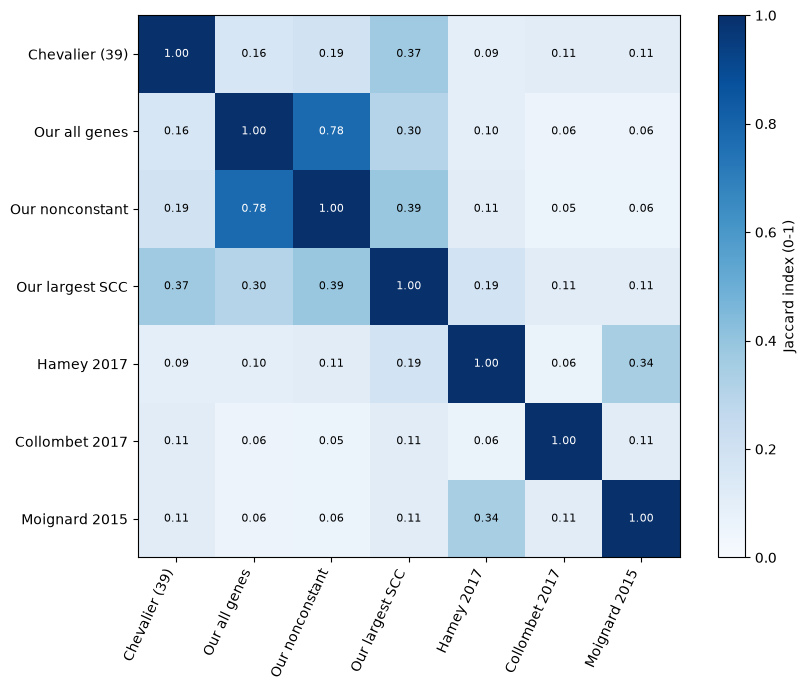

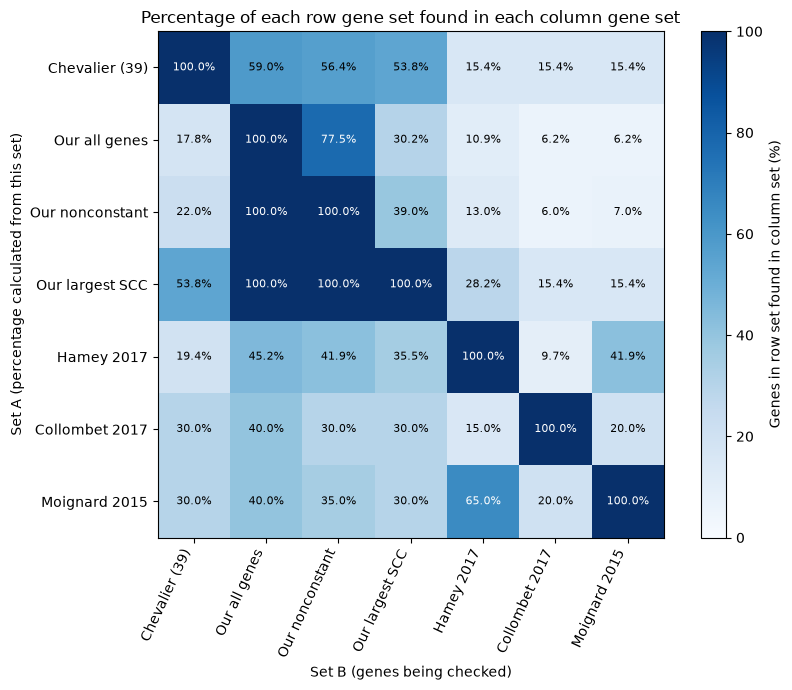

paper_only 18 ['ATF7', 'EBF1', 'ESR1', 'FOXO3', 'FOXP2', 'HBP1', 'HNF4A', 'IKZF1', 'IRF1', 'JUNB', 'KLF1', 'KLF6', 'NRF1', 'STAT6', 'TBP', 'TBX21', 'TCF12', 'ZEB2']
Our_core_only 18 ['AR', 'CREB1', 'E2F6', 'ELF3', 'ETS1', 'ETS2', 'GATA3', 'IRF4', 'LEF1', 'MITF', 'NR3C1', 'PAX5', 'PPARG', 'TAL1', 'TCF4', 'TCF7', 'TCF7L2', 'TFAP2A']
paper_and_Our_core 21 ['ATF3', 'CEBPA', 'CREM', 'E2F1', 'FLI1', 'FOS', 'GATA1', 'GFI1B', 'IRF2', 'JUN', 'MEF2C', 'MYB', 'MYC', 'NFATC1', 'RELA', 'RUNX1', 'SP1', 'SPI1', 'STAT1', 'STAT3', 'TRP53']


In [38]:
# Calculate gene overlap for every ordered pair of sets.
rows = []
for name_a, a in comparisons.items():
    for name_b, b in comparisons.items():
        shared = a & b
        union = a | b
        n_shared = len(shared)
        rows.append({
            'set_a': name_a,
            'set_b': name_b,
            'n_a': len(a),
            'n_b': len(b),
            'intersection': n_shared,
            'jaccard': n_shared / len(union) if union else np.nan,
            'percent_of_a_in_b': 100 * n_shared / len(a) if a else np.nan,
            'percent_of_b_in_a': 100 * n_shared / len(b) if b else np.nan,
            'common_genes': '; '.join(sorted(shared)),
        })

# Save a table containing both directional percentages and the Jaccard index.
overlap_df = pd.DataFrame(rows)
overlap_df.to_csv(OUT / 'pairwise_gene_overlaps.csv', index=False)

# Compare our final SCC (set A) with each published set (set B).
print('percent_of_a_in_b: percentage of our SCC genes found in the comparison set')
print('percent_of_b_in_a: percentage of the comparison set genes found in our SCC')
display(overlap_df.loc[
    (overlap_df.set_a == 'Our largest SCC') &
    (overlap_df.set_b != 'Our largest SCC'),
    ['set_b', 'n_a', 'n_b', 'intersection', 'jaccard',
     'percent_of_a_in_b', 'percent_of_b_in_a', 'common_genes']
])

# Plot the symmetric Jaccard index (0-1) as the original comparison.
set_order = list(comparisons)
jaccard = overlap_df.pivot(index='set_a', columns='set_b', values='jaccard').reindex(
    index=set_order, columns=set_order)
fig, ax = plt.subplots(figsize=(9, 7))
im = ax.imshow(jaccard.values, vmin=0, vmax=1, cmap='Blues')
ax.set_xticks(range(len(set_order)), set_order, rotation=65, ha='right')
ax.set_yticks(range(len(set_order)), set_order)
for i in range(len(set_order)):
    for j in range(len(set_order)):
        value = jaccard.iloc[i, j]
        ax.text(j, i, f'{value:.2f}', ha='center', va='center',
                color='white' if value >= .6 else 'black', fontsize=8)
fig.colorbar(im, ax=ax, label='Jaccard index (0-1)')
fig.tight_layout()
fig.savefig(OUT / 'gene_overlap_jaccard.png', dpi=180)
plt.show()

# Plot the directional percentage: row set's genes found in the column set.
percent_overlap = overlap_df.pivot(
    index='set_a', columns='set_b', values='percent_of_a_in_b'
).reindex(index=set_order, columns=set_order)
fig, ax = plt.subplots(figsize=(9, 7))
im = ax.imshow(percent_overlap.values, vmin=0, vmax=100, cmap='Blues')
ax.set_xticks(range(len(set_order)), set_order, rotation=65, ha='right')
ax.set_yticks(range(len(set_order)), set_order)
ax.set_xlabel('Set B (genes being checked)')
ax.set_ylabel('Set A (percentage calculated from this set)')
ax.set_title('Percentage of each row gene set found in each column gene set')
for i in range(len(set_order)):
    for j in range(len(set_order)):
        value = percent_overlap.iloc[i, j]
        ax.text(j, i, f'{value:.1f}%' if np.isfinite(value) else 'NA',
                ha='center', va='center',
                color='white' if value >= 60 else 'black', fontsize=8)
fig.colorbar(im, ax=ax, label='Genes in row set found in column set (%)')
fig.tight_layout()
fig.savefig(OUT / 'gene_overlap_directional_percent.png', dpi=180)
plt.show()

# Export genes unique to either SCC or paper, and those they share.
for label, genes in [
    ('paper_only', set(paper_components) - core_nodes),
    ('Our_core_only', core_nodes - set(paper_components)),
    ('paper_and_Our_core', core_nodes & set(paper_components)),
]:
    print(label, len(genes), sorted(genes))
    (OUT / f'{label}.txt').write_text('\n'.join(sorted(genes)) + '\n')


## 7. Interaction graphs: Our SCC vs. published 39-gene subgraph

Both graphs are induced from the same **full original DoRothEA SIF** for a controlled comparison. Our selected SCC's edges should match the candidate SIF, but confirm this explicitly. Degree histograms and per-gene summaries are exported.

,network,nodes,signed_edges,n_scc,largest_scc,mean_indegree,mean_outdegree
0,Chevalier 39,39,137,6,34,3.512821,3.512821
1,Our SCC,39,157,1,39,4.025641,4.025641


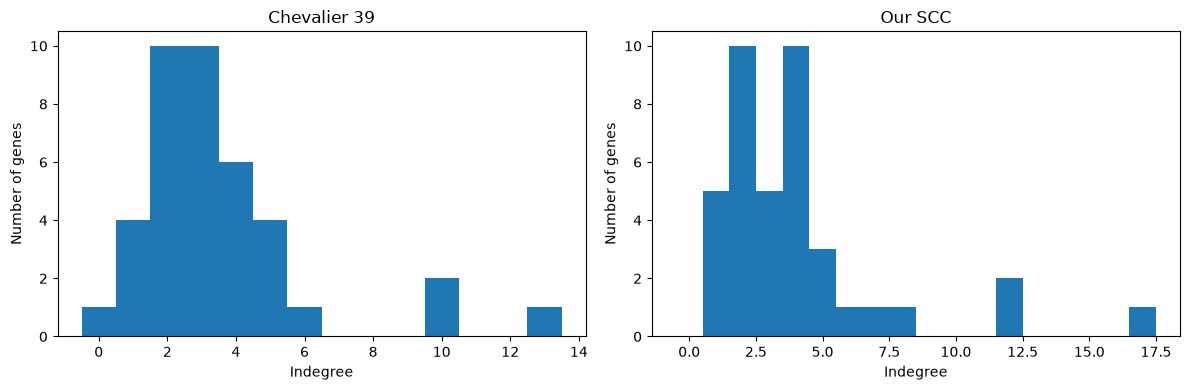

In [39]:
def induced_graph(genes, sif):
    e = sif.loc[sif.source.isin(genes) & sif.target.isin(genes)]
    graph = nx.MultiDiGraph()
    graph.add_nodes_from(genes)
    graph.add_edges_from((r.source,r.target,{'sign':r.sign}) for r in e.itertuples(index=False))
    return graph

paper_graph = induced_graph(paper_components, full_edges)
Our_graph = induced_graph(core_nodes, candidate_edges)
network_stats=[]
for label,g in [('Chevalier 39',paper_graph), ('Our SCC', Our_graph)]:
    network_stats.append({'network':label, 'nodes':g.number_of_nodes(), 'signed_edges':g.number_of_edges(),
                          'n_scc':nx.number_strongly_connected_components(g),
                          'largest_scc':max(map(len,nx.strongly_connected_components(g)),default=0),
                          'mean_indegree':float(np.mean([d for _,d in g.in_degree()])) if len(g) else 0,
                          'mean_outdegree':float(np.mean([d for _,d in g.out_degree()])) if len(g) else 0})
display(pd.DataFrame(network_stats))
pd.DataFrame(network_stats).to_csv(OUT/'network_statistics.csv',index=False)

degree_rows=[]
for label,g in [('Chevalier 39',paper_graph), ('Our SCC',Our_graph)]:
    for gene in g.nodes():
        degree_rows.append({'selection':label,'gene':gene,'indegree':g.in_degree(gene),
                            'outdegree':g.out_degree(gene),'total_degree':g.degree(gene)})
degrees = pd.DataFrame(degree_rows)
degrees.to_csv(OUT/'gene_degrees.csv',index=False)
fig,axs=plt.subplots(1,2,figsize=(12,4))
for ax,(label,g) in zip(axs,[('Chevalier 39',paper_graph),('Our SCC',Our_graph)]):
    indegrees=[d for _,d in g.in_degree()]
    ax.hist(indegrees,bins=range(0,max(indegrees,default=0)+2),align='left')
    ax.set(title=label,xlabel='Indegree',ylabel='Number of genes')
fig.tight_layout(); fig.savefig(OUT/'indegree_comparison.png',dpi=180); plt.show()

### Network visualization

Use the same spring-layout convention for both induced networks. Regulation signs remain visible (positive vs. negative); edge direction is also drawn. For crowded networks, rely on the tabular exports for exact interactions.

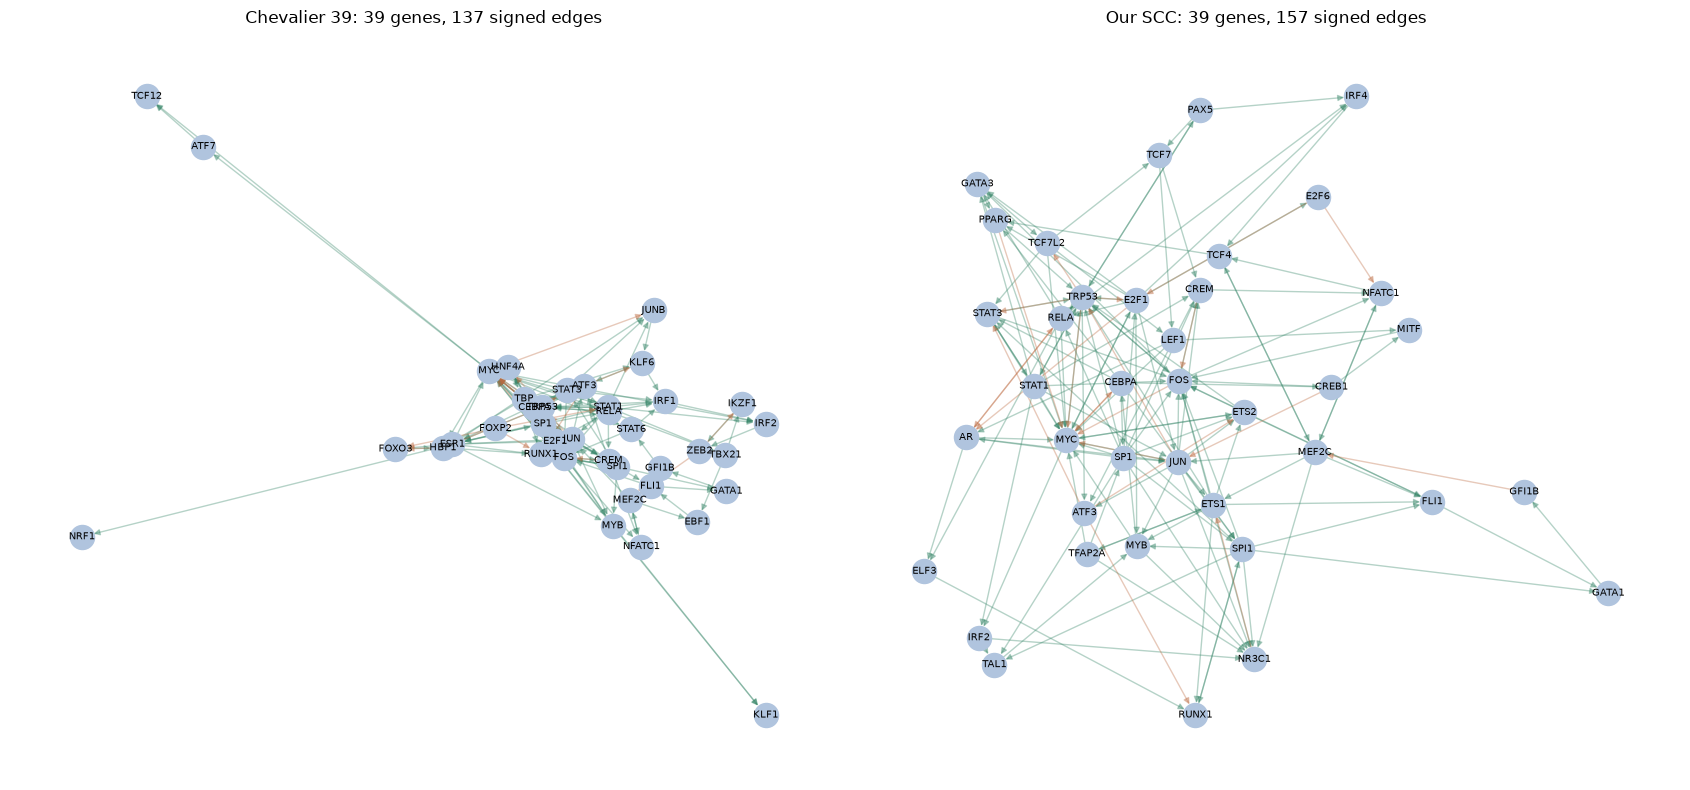

In [40]:
fig, axs = plt.subplots(1, 2, figsize=(17, 8))
for ax, (label, gr) in zip(axs, [('Chevalier 39', paper_graph), ('Our SCC', Our_graph)]):
    pos = nx.spring_layout(nx.DiGraph(gr), seed=17)
    nx.draw_networkx_nodes(gr, pos, ax=ax, node_size=300, node_color='lightsteelblue')
    nx.draw_networkx_labels(gr, pos, ax=ax, font_size=7)
    positive = [(u,v) for u,v,d in gr.edges(data=True) if str(d.get('sign')).strip() in {'1','+','+1','->'}]
    negative = [(u,v) for u,v,d in gr.edges(data=True) if str(d.get('sign')).strip() in {'-1','-','0','-|'}]
    unknown = [(u,v) for u,v,d in gr.edges(data=True) if (u,v) not in positive and (u,v) not in negative]
    nx.draw_networkx_edges(gr, pos, edgelist=positive, edge_color='#338466', ax=ax, arrows=True, alpha=.36, arrowsize=9)
    nx.draw_networkx_edges(gr, pos, edgelist=negative, edge_color='#bd6a40', ax=ax, arrows=True, alpha=.36, arrowsize=9)
    nx.draw_networkx_edges(gr, pos, edgelist=unknown, edge_color='#777777', ax=ax, arrows=True, alpha=.3, arrowsize=9)
    ax.set_title(f'{label}: {gr.number_of_nodes()} genes, {gr.number_of_edges()} signed edges')
    ax.axis('off')
fig.tight_layout()
fig.savefig(OUT/'network_comparison_signed.png', dpi=190)
plt.show()

## 8. Six-state observations: missingness, activity and branch differences

This reproduces the original notebook's binarized-observation analysis, now for **both** component sets. All raw observation values are retained in the exported tables; the notebook does not silently re-encode missing observations. The original Case Study 1 CSV has 0=OFF, 1=ON, NaN=not determined; both determined states are retained.

In [41]:
# Use the correctly normalized observation table: 0=OFF, 1=ON, NaN/None=ND.
for label, genes in [('paper',set(paper_components)), ('Our_core',core_nodes),
                     ('Our_nonconstant',nonconstant_nodes)]:
    cols=sorted(genes & set(obs_df.columns))
    observed=obs_df.reindex(columns=cols)
    observed.to_csv(OUT/f'{label}_S0_S5_observations.csv')
    print(label,'total',len(genes),'determined in at least one state',
          sum(observed.notna().any(axis=0)))
    display(observed.iloc[:,:min(30,len(cols))])
for a,b in [('S2','S4'),('S2','S5'),('S4','S5')]:
    cols=sorted(core_nodes & set(obs_df.columns))
    x=obs_df.loc[a,cols];y=obs_df.loc[b,cols]
    mask=x.notna() & y.notna()
    different=[g for g in cols if bool(mask[g]) and x[g]!=y[g]]
    print(a,b,':',len(different),'determined differences:',different)


paper total 39 determined in at least one state 24


,ATF7,EBF1,ESR1,FOS,GATA1,GFI1B,HBP1,HNF4A,IKZF1,IRF1,...,MYB,MYC,NFATC1,NRF1,SPI1,STAT1,STAT3,STAT6,TCF12,ZEB2
S0,0,NaN,0,0,0,0,0,NaN,NaN,1,...,NaN,0.0,1,0,1,0,1,0,0,1
S1,0,NaN,0,1,0,0,1,NaN,0.0,1,...,NaN,0.0,0,0,1,0,1,0,0,0
S2,0,NaN,0,1,0,0,1,NaN,0.0,1,...,0.0,0.0,0,0,1,0,1,0,0,0
S3,1,0.0,0,0,0,0,1,NaN,NaN,1,...,NaN,NaN,0,1,1,1,0,1,0,1
S4,1,0.0,0,0,0,0,1,NaN,NaN,1,...,NaN,NaN,0,0,1,0,1,1,1,1
S5,0,1.0,0,1,1,1,1,NaN,1.0,0,...,1.0,NaN,0,0,0,0,1,0,0,0


Our_core total 39 determined in at least one state 13


,E2F6,ETS1,FOS,GATA1,GFI1B,JUN,LEF1,MEF2C,MYB,MYC,NFATC1,SPI1,STAT1,STAT3,TCF7
S0,0,1.0,0,0,0,1,NaN,1,NaN,0.0,1,1,0,1,NaN
S1,0,NaN,1,0,0,1,NaN,1,NaN,0.0,0,1,0,1,NaN
S2,0,NaN,1,0,0,1,NaN,1,0.0,0.0,0,1,0,1,NaN
S3,1,NaN,0,0,0,0,NaN,0,NaN,NaN,0,1,1,0,NaN
S4,0,NaN,0,0,0,0,NaN,1,NaN,NaN,0,1,0,1,NaN
S5,0,NaN,1,1,1,1,NaN,1,1.0,NaN,0,0,0,1,NaN


Our_nonconstant total 100 determined in at least one state 72


,ANXA1,BCL2,BID,BIRC2,BIRC5,CCL3,CCNA2,CCNB1,CD1D1,CD34,...,ETS1,EZR,FES,FOS,GATA1,GCLC,GFI1B,HSPA9,IL12A,IRF8
S0,0,1,0,1,0,0,0,0,0,1,...,1.0,1,0,0,0,0,0,NaN,1,1
S1,1,0,0,0,0,0,0,0,1,1,...,NaN,0,0,1,0,0,0,NaN,0,0
S2,0,0,0,0,0,1,0,0,0,1,...,NaN,0,1,1,0,0,0,0.0,1,0
S3,0,0,1,1,1,0,1,1,0,1,...,NaN,1,1,0,0,1,0,1.0,0,0
S4,1,1,1,0,1,0,0,0,0,1,...,NaN,1,1,0,0,0,0,NaN,0,1
S5,0,0,0,0,0,0,0,0,1,0,...,NaN,0,0,1,1,0,1,0.0,0,0


S2 S4 : 2 determined differences: ['FOS', 'JUN']
S2 S5 : 4 determined differences: ['GATA1', 'GFI1B', 'MYB', 'SPI1']
S4 S5 : 5 determined differences: ['FOS', 'GATA1', 'GFI1B', 'JUN', 'SPI1']


## 9. GO enrichment of chosen solution and paper/reference sets on the original GRN universe

This section reproduces the original extended analysis for the selected solution, in addition to the all-answer conditional enrichment above. Gene-set overlaps with a selected MSigDB-seed-derived search space remain exploratory.

GO BP gene sets: 7781 Original GRN annotated universe: 959
Chevalier (39) in background 39 of 39
Our all genes in background 129 of 129
Our nonconstant in background 100 of 100
Our largest SCC in background 39 of 39
Hamey 2017 in background 19 of 31
Collombet 2017 in background 14 of 20
Moignard 2015 in background 12 of 20


,go_term,n_overlap,fdr,overlap_genes
9676,GOBP_POSITIVE_REGULATION_OF_TRANSCRIPTION_BY_R...,37,6.160238e-18,AR; ATF3; CEBPA; CREB1; CREM; E2F1; ELF3; ETS1...
9651,GOBP_POSITIVE_REGULATION_OF_RNA_METABOLIC_PROCESS,37,9.948676e-16,AR; ATF3; CEBPA; CREB1; CREM; E2F1; ELF3; ETS1...
9129,GOBP_NEGATIVE_REGULATION_OF_NUCLEOBASE_CONTAIN...,33,1.369130e-13,AR; ATF3; CEBPA; CREB1; CREM; E2F1; E2F6; ELF3...
9170,GOBP_NEGATIVE_REGULATION_OF_RNA_BIOSYNTHETIC_P...,32,1.930572e-13,AR; ATF3; CEBPA; CREB1; CREM; E2F1; E2F6; ELF3...
9187,GOBP_NEGATIVE_REGULATION_OF_TRANSCRIPTION_BY_R...,30,5.641921e-13,AR; ATF3; CEBPA; CREM; E2F1; E2F6; ETS2; GATA1...
8966,GOBP_MYELOID_CELL_DIFFERENTIATION,24,1.298893e-11,CEBPA; CREB1; ETS1; FLI1; FOS; GATA1; GATA3; G...
8972,GOBP_MYELOID_LEUKOCYTE_DIFFERENTIATION,18,5.007616e-10,CEBPA; CREB1; FOS; GATA1; GATA3; GFI1B; IRF4; ...
9425,GOBP_POSITIVE_REGULATION_OF_CELL_DIFFERENTIATION,24,8.590747e-09,AR; CEBPA; CREB1; E2F1; ETS1; FOS; GATA1; GATA...
9558,GOBP_POSITIVE_REGULATION_OF_MIRNA_METABOLIC_PR...,13,8.590747e-09,AR; ETS1; FOS; GATA3; JUN; MYB; MYC; NR3C1; PP...
10104,GOBP_REGULATION_OF_MYELOID_CELL_DIFFERENTIATION,16,8.590747e-09,CREB1; ETS1; FOS; GATA1; GFI1B; JUN; LEF1; MEF...


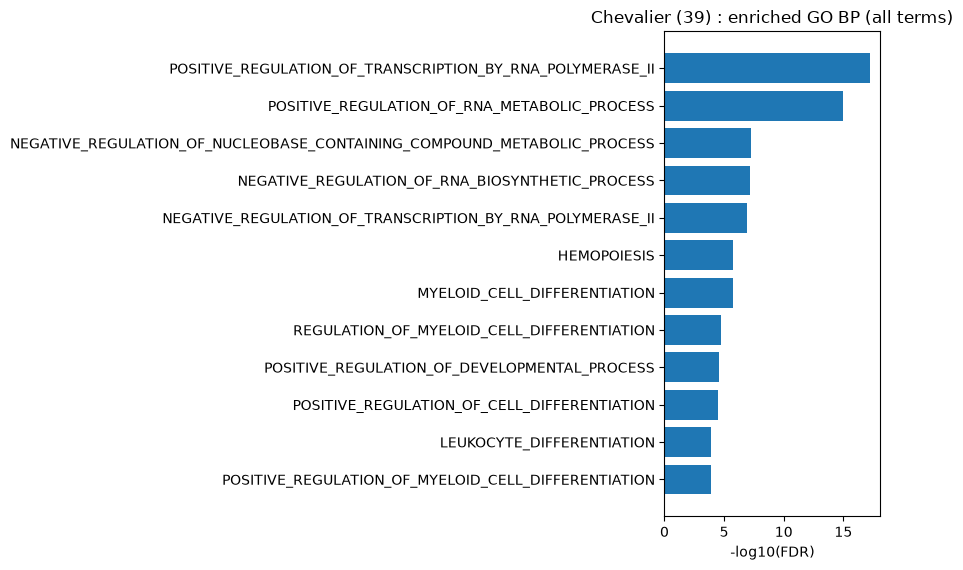

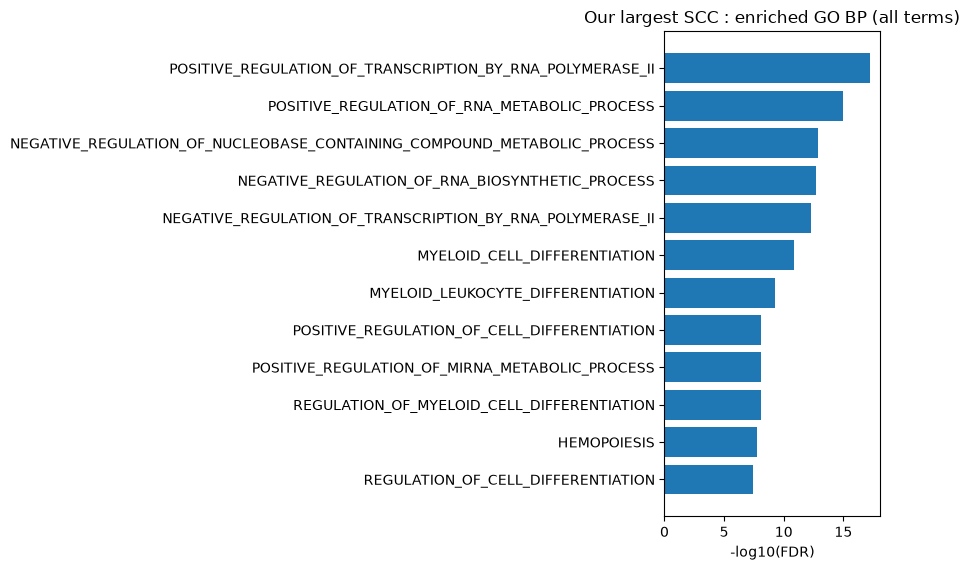

In [42]:
from scipy.stats import hypergeom
from statsmodels.stats.multitest import multipletests

def load_gobp_gmt(path):
    terms={}
    with path.open(encoding='utf-8') as f:
        for line in f:
            p=line.rstrip('\n').split('\t')
            if len(p)>=3 and p[0].startswith('GOBP_'):
                terms[p[0]]={g.strip().upper() for g in p[2:] if g.strip()}
    return terms

if not MSIGDB_GMT.is_file():
    print('GO skipped: download the full mouse MSigDB GMT with the preceding MSigDB notebook first:', MSIGDB_GMT)
    go_results=pd.DataFrame()

else:
    terms=load_gobp_gmt(MSIGDB_GMT)

    full_domain=set(full_edges.source) | set(full_edges.target)
    annotated=set().union(*terms.values()) if terms else set()
    background=full_domain & annotated

    if not background:
        raise RuntimeError('Empty background; inspect GO gene symbols and GRN symbols.')

    print('GO BP gene sets:',len(terms),'Original GRN annotated universe:',len(background))

    rows=[]

    for label, genes in comparisons.items():
        tested=genes & background

        print(label, 'in background',len(tested),'of',len(genes))

        if not tested:
            continue

        pvals=[]
        tmp=[]

        for term,gset in terms.items():
            t=gset & background

            if len(t)<5:
                continue

            overlap=tested & t

            p=float(hypergeom.sf(
                len(overlap)-1,
                len(background),
                len(t),
                len(tested)
            ))

            tmp.append({
                'selection':label,
                'go_term':term,
                'n_background':len(background),
                'n_set_in_background':len(t),
                'n_selection_in_background':len(tested),
                'n_overlap':len(overlap),
                'overlap_genes':'; '.join(sorted(overlap)),
                'pvalue':p
            })

            pvals.append(p)

        if not pvals:
            continue

        adjusted=multipletests(pvals,method='fdr_bh')[1]

        for row,q in zip(tmp,adjusted):
            row['fdr']=q

        rows.extend(tmp)

    go_results=pd.DataFrame(rows)

    go_results.to_csv(
        OUT/'GO_BP_enrichment_all_selections.csv',
        index=False
    )

    if not go_results.empty:

        significant=go_results[
            (go_results.fdr<.05) &
            (go_results.n_overlap>=2)
        ]

        significant.to_csv(
            OUT/'GO_BP_significant_ALL_terms_fdr05.csv',
            index=False
        )

        display(
            significant[
                significant.selection=='Our largest SCC'
            ].nsmallest(20,'fdr')[
                ['go_term','n_overlap','fdr','overlap_genes']
            ]
        )

        for label in ['Chevalier (39)','Our largest SCC']:

            top=significant[
                significant.selection==label
            ].nsmallest(12,'fdr').iloc[::-1]

            if len(top):

                fig,ax=plt.subplots(
                    figsize=(9,max(3,0.4*len(top)+1))
                )

                ax.barh(
                    top.go_term.str.replace('GOBP_','',regex=False),
                    -np.log10(top.fdr.clip(lower=1e-300))
                )

                ax.set(
                    xlabel='-log10(FDR)',
                    title=label+' : enriched GO BP (all terms)'
                )

                fig.tight_layout()

                fig.savefig(
                    OUT/f'GO_BP_ALL_{"paper" if label.startswith("Chevalier") else "Our_core"}.png',
                    dpi=170
                )

                plt.show()

## 10. Final summary and BoNesis handoff

Summarize the proven-optimal selected genes, nonconstant genes, and largest SCC. The exported SCC can be used for model sampling, but its ability to reproduce S0–S5 dynamics must still be checked.


In [43]:
summary = pd.DataFrame([
    {
        'selection': 'Chevalier 39', 'n_genes': len(paper_components),
        'n_signed_edges': len(full_edges[
            full_edges.source.isin(paper_components) & full_edges.target.isin(paper_components)])
    },
    {
        'selection': 'Our optimal Clingo answer', 'n_genes': len(selected_nodes),
        'n_signed_edges': len(candidate_edges[
            candidate_edges.source.isin(selected_nodes) & candidate_edges.target.isin(selected_nodes)])
    },
    {
        'selection': 'Our nonconstant set', 'n_genes': len(nonconstant_nodes),
        'n_signed_edges': len(nonconstant_edges)
    },
    {
        'selection': 'Our largest SCC', 'n_genes': len(core_nodes),
        'n_signed_edges': len(core_edges)
    },
])
summary.to_csv(OUT / 'summary.csv', index=False)
display(summary)

# The GO table is produced in Section 9, if the MSigDB file was available.
if 'go_results' in globals() and not go_results.empty:
    terms = go_results[
        (go_results.selection == 'Our largest SCC') &
        (go_results.n_overlap >= 2)
    ].nsmallest(20, 'fdr')
    print('Top GO:BP terms for the optimal SCC:')
    display(terms[['go_term', 'n_overlap', 'fdr', 'overlap_genes']])
    terms.to_csv(OUT / 'chosen_core_top_GO_terms.csv', index=False)

print('Selected Clingo answer:', selected_answer_id, '(proven optimal)')
print('Outputs:', OUT.resolve())
print('BoNesis inputs:', OUT / 'core_genes.txt', 'and', OUT / 'synthesis_core_network.sif')
print('SCC reduction has NOT been independently shown to preserve S0-S5 reachability.')


,selection,n_genes,n_signed_edges
0,Chevalier 39,39,137
1,Our optimal Clingo answer,129,556
2,Our nonconstant set,100,341
3,Our largest SCC,39,157


Top GO:BP terms for the optimal SCC:


,go_term,n_overlap,fdr,overlap_genes
9676,GOBP_POSITIVE_REGULATION_OF_TRANSCRIPTION_BY_R...,37,6.160238e-18,AR; ATF3; CEBPA; CREB1; CREM; E2F1; ELF3; ETS1...
9651,GOBP_POSITIVE_REGULATION_OF_RNA_METABOLIC_PROCESS,37,9.948676e-16,AR; ATF3; CEBPA; CREB1; CREM; E2F1; ELF3; ETS1...
9129,GOBP_NEGATIVE_REGULATION_OF_NUCLEOBASE_CONTAIN...,33,1.369130e-13,AR; ATF3; CEBPA; CREB1; CREM; E2F1; E2F6; ELF3...
9170,GOBP_NEGATIVE_REGULATION_OF_RNA_BIOSYNTHETIC_P...,32,1.930572e-13,AR; ATF3; CEBPA; CREB1; CREM; E2F1; E2F6; ELF3...
9187,GOBP_NEGATIVE_REGULATION_OF_TRANSCRIPTION_BY_R...,30,5.641921e-13,AR; ATF3; CEBPA; CREM; E2F1; E2F6; ETS2; GATA1...
8966,GOBP_MYELOID_CELL_DIFFERENTIATION,24,1.298893e-11,CEBPA; CREB1; ETS1; FLI1; FOS; GATA1; GATA3; G...
8972,GOBP_MYELOID_LEUKOCYTE_DIFFERENTIATION,18,5.007616e-10,CEBPA; CREB1; FOS; GATA1; GATA3; GFI1B; IRF4; ...
9425,GOBP_POSITIVE_REGULATION_OF_CELL_DIFFERENTIATION,24,8.590747e-09,AR; CEBPA; CREB1; E2F1; ETS1; FOS; GATA1; GATA...
9558,GOBP_POSITIVE_REGULATION_OF_MIRNA_METABOLIC_PR...,13,8.590747e-09,AR; ETS1; FOS; GATA3; JUN; MYB; MYC; NR3C1; PP...
10104,GOBP_REGULATION_OF_MYELOID_CELL_DIFFERENTIATION,16,8.590747e-09,CREB1; ETS1; FOS; GATA1; GFI1B; JUN; LEF1; MEF...


Selected Clingo answer: 195 (proven optimal)
Outputs: /home/eren/CSBC_CLEAN/Results/Component_analysis_outputs
BoNesis inputs: ../Results/Component_analysis_outputs/core_genes.txt and ../Results/Component_analysis_outputs/synthesis_core_network.sif
SCC reduction has NOT been independently shown to preserve S0-S5 reachability.
